In [ ]:
import mrcfile
import starfile
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.fft
import matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def plot_cc(im, matrix, aunps, tilt=0, r=6):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    projection = torch.mm(matrix, aunps.T).T[:,[0,1]]
    model_image = torch.ones(im.shape[0], im.shape[1], device=device)
    y = torch.arange(0, model_image.shape[0], device=device)
    x = torch.arange(0, model_image.shape[1], device=device)
    grid_y, grid_x = torch.meshgrid(y, x)
    for i in range(projection.shape[0]):
        temp_y = grid_y - projection[i, 1]
        temp_x = grid_x - projection[i, 0]
        # Create the mask in-place
        mask = temp_x.pow_(2).add_(temp_y.pow_(2)) <= r*r

        # Apply the mask
        model_image[mask] -= 1

    #plt.imshow(model_image.cpu())
    #plt.show()
    #plt.imshow(im.cpu())
    #plt.show()
    image_product = torch.fft.fft2(im) * torch.fft.fft2(model_image).conj()
    cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
    sub = cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+100,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+100]
    #plt.imshow(sub.cpu())
    #plt.show()
    #plt.imshow(cc_image.real.cpu())
    #plt.show()
    # Where is the peak?
    from skimage.registration import phase_cross_correlation
    shift, error, diffphase = phase_cross_correlation(im.cpu().numpy(), model_image.cpu().numpy(),normalization=None)
    #print(shift)
    #print(error)
    #print(diffphase)

    # find the peak in sub
    #print((sub==torch.max(sub)).nonzero())

    # Simple crosscorrelation
    cc_value = model_image * im
    #print(cc_value.sum())
    #print(torch.max(sub))
    return shift
    #return torch.max(sub)-torch.median(sub)

In [7]:
starfile_path = Path(('/scratch_pompeii/elferich/gouaux_tomo/ProcessingJE/manuscript01/relion_reconstruction/ImportTomo/job002/tomograms.star'))
data = starfile.read(starfile_path)
matrices = data['20231017_EGmilled24-2_60']
matrices = matrices.iloc[:,[0,1,2,3]].to_numpy()
matrices = [[s.strip('[]').split(',') for s in matrix] for matrix in matrices]
matrices = np.array([np.vstack([[float(x) for x in row] for row in matrix]) for matrix in matrices])
matrices = torch.tensor(matrices,device=device,requires_grad=True)

mrcfile_path = Path('/scratch_pompeii/elferich/gouaux_tomo/ProcessingJE/manuscript01/relion_reconstruction/tomograms/20231017_EGmilled24-2_60/20231017_EGmilled24-2_60.mrc')
im_data = mrcfile.read(mrcfile_path)
im_data = torch.tensor(im_data,device='cpu')

aunps = np.genfromtxt('/scratch_pompeii/elferich/gouaux_tomo/ProcessingJE/manuscript01/relion_reconstruction/finding_ampa/pipeline_data/pipeline1/visualization/20231017_EGmilled24-2_68/combined_aunp.txt',delimiter=' ',usecols=(2,3,4))
aunps = aunps * 4.0
ones = np.ones((aunps.shape[0], 1))
aunps = np.hstack((aunps, ones)) 
aunps = torch.tensor(aunps,device=device)

In [8]:
matrices[15]

tensor([[-1.5944e-01, -9.8720e-01,  1.9481e-03,  4.9934e+03],
        [ 9.8713e-01, -1.5945e-01, -1.2061e-02,  4.5169e+02],
        [ 1.2217e-02,  0.0000e+00,  9.9993e-01, -5.1955e+02],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]], device='cuda:0',
       dtype=torch.float64, grad_fn=<SelectBackward0>)

torch.Size([844, 1188])


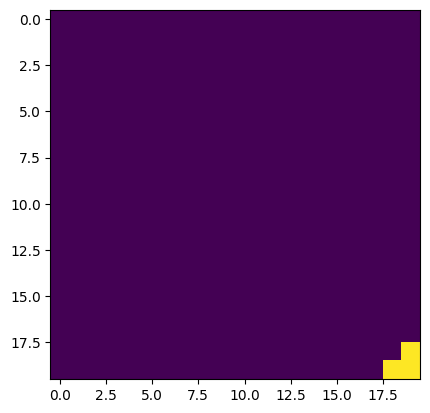

In [17]:
from libtilt.shift.shift_image import shift_2d
from libtilt.rescaling.rescale_fourier import rescale_2d
im = im_data[15].to(device).detach()
im, _ = rescale_2d(im, source_spacing=1.0, target_spacing=4.0, maintain_center=True)
print(im.shape)
r=8.3 / 4.0
r_aunps = aunps / 4.0
circle = torch.zeros(im.shape[0],im.shape[1],device=device)
y = torch.arange(0, im.shape[0], device=device)
x = torch.arange(0, im.shape[1], device=device)
grid_y, grid_x = torch.meshgrid(y, x)
temp_y = grid_y - 9.5
temp_x = grid_x - 9.5
# Create the mask in-place
circle = (temp_x.pow_(2).add_(temp_y.pow_(2)) <= r*r) * 1.0
circle = shift_2d(circle, shifts=torch.tensor([-10, -10],device=device))
plt.imshow(circle.cpu()[-20:,-20:])
del grid_x, grid_y, temp_x, temp_y
torch.cuda.synchronize()


0 -4640.074276979234


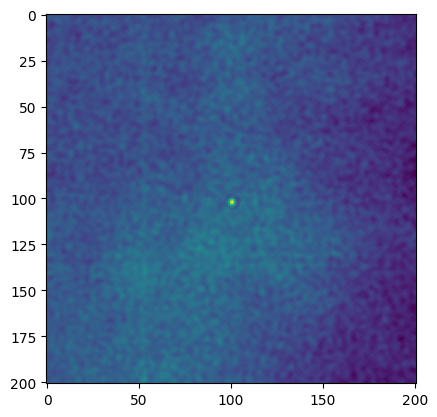

20 -5010.290364558554


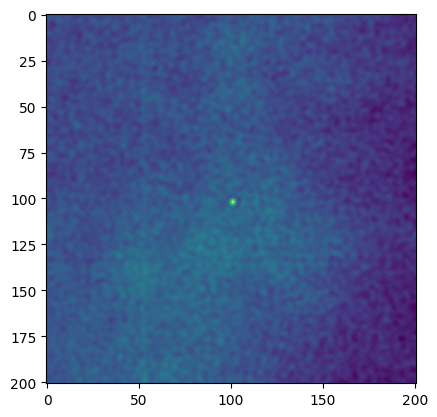

40 -5065.597792180837


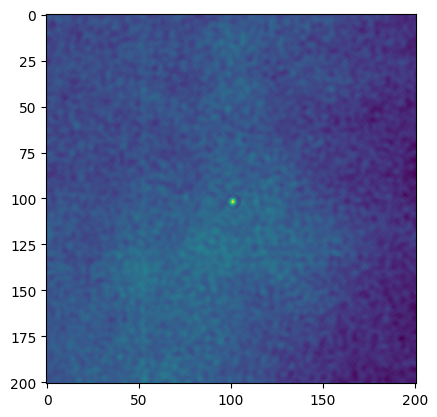

60 -5077.542410966191


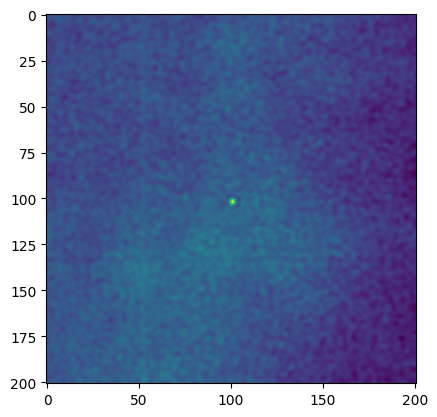

80 -5078.5326116225915


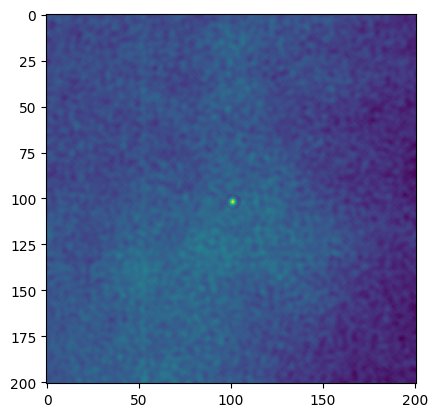

100 -5078.674071099449


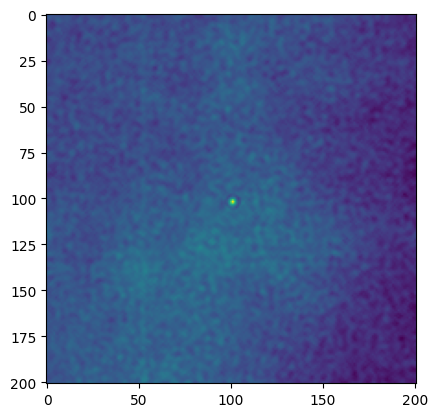

120 -5078.765958800432


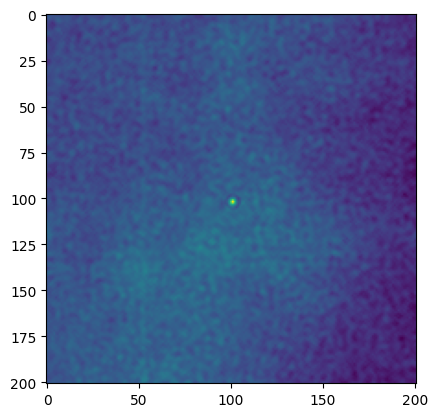

140 -5078.847238506729


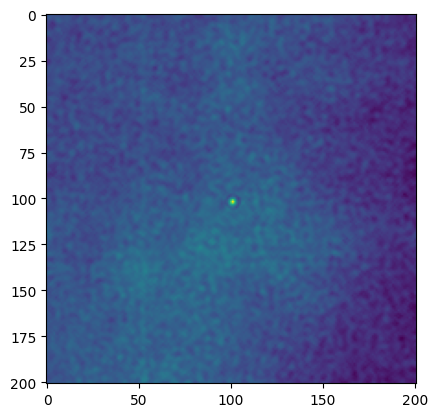

160 -5078.932343043176


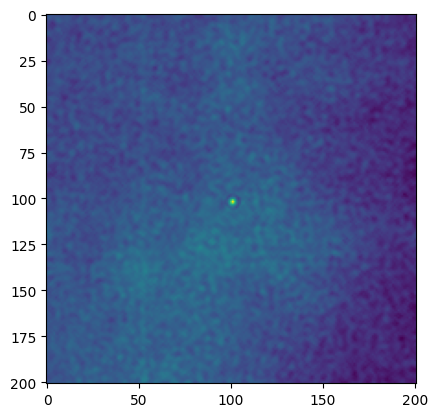

180 -5079.022588866646


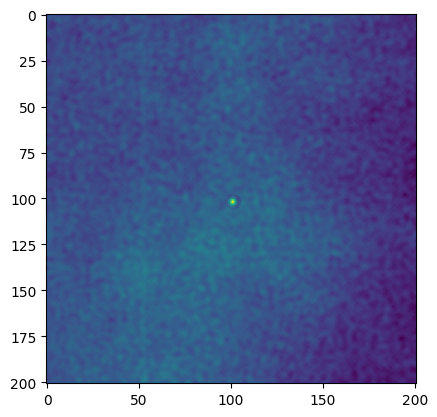

200 -5079.117877700686


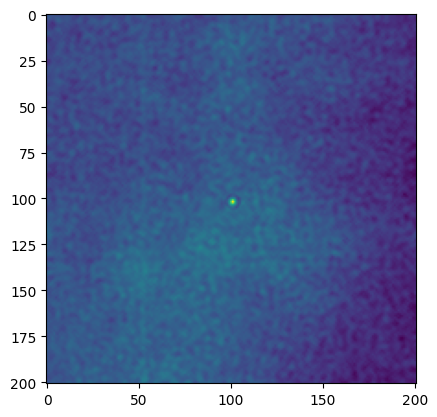

220 -5079.217945896511


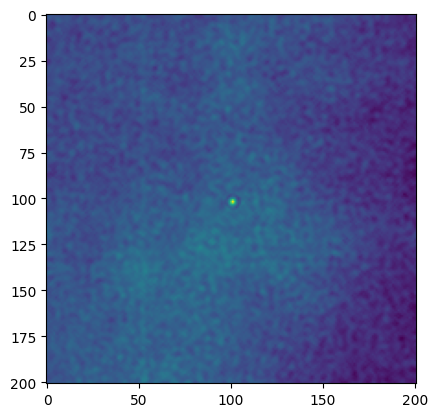

240 -5079.322551334466


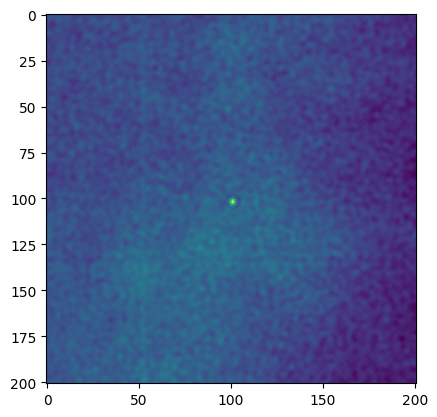

260 -5079.431477530459


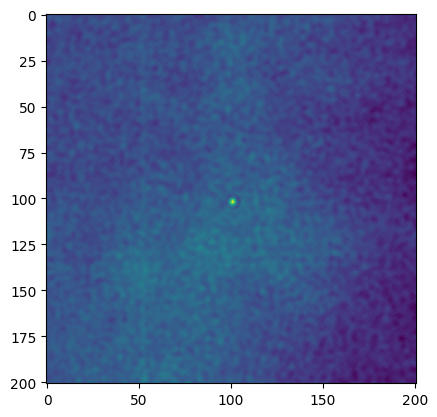

280 -5079.544531398664


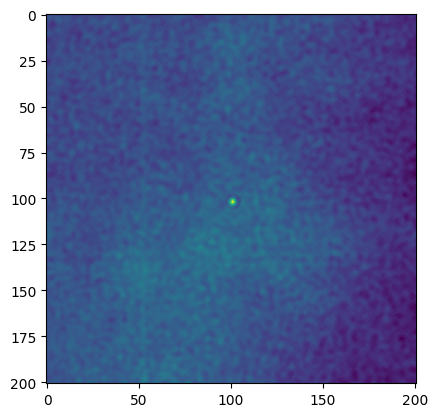

300 -5079.661538689019


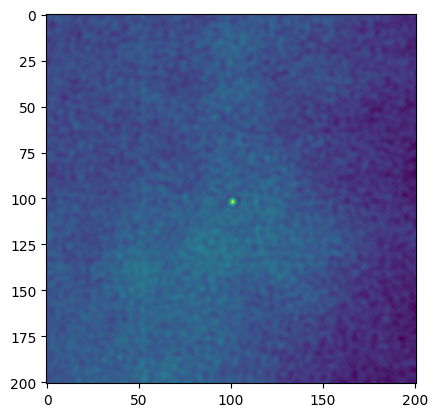

320 -5079.782340820166


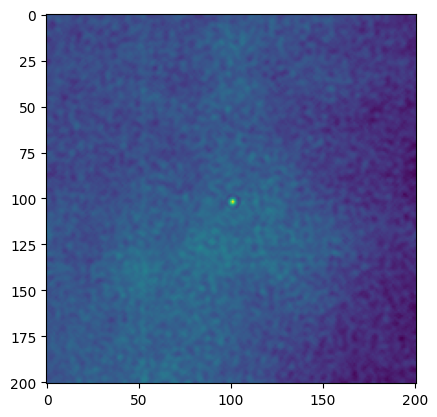

340 -5079.906792384296


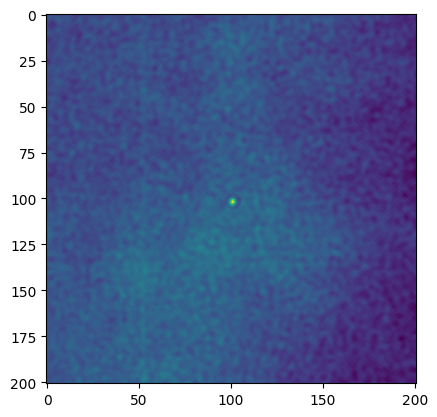

360 -5080.034759173926


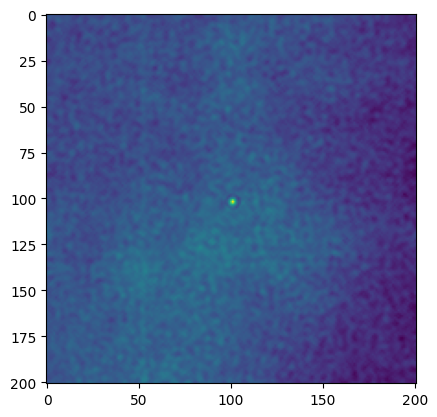

380 -5080.1661166015765


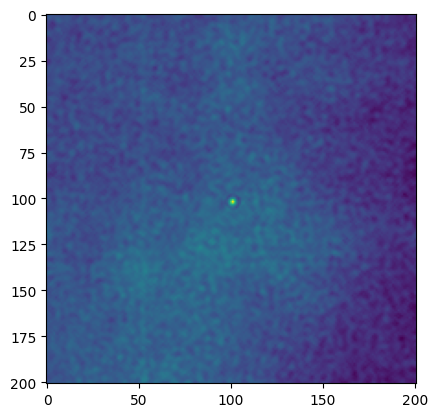

400 -5080.30074841671


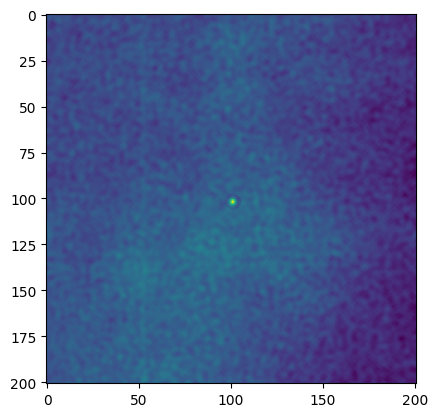

420 -5080.438545652629


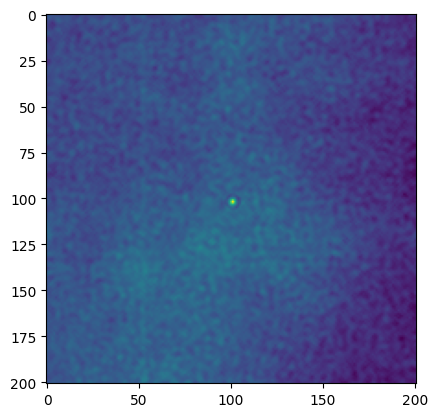

440 -5080.579405753597


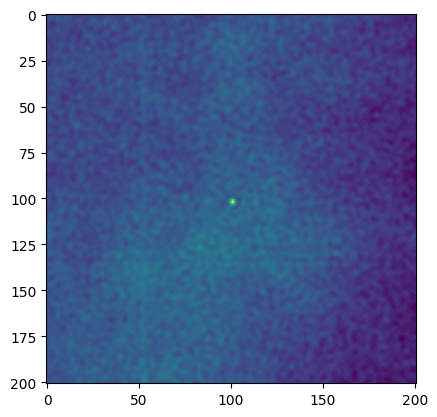

460 -5080.723231842865


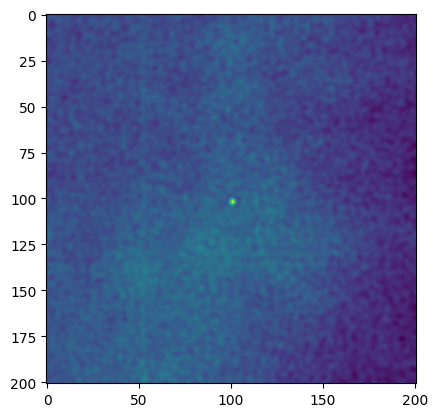

480 -5080.869932106376


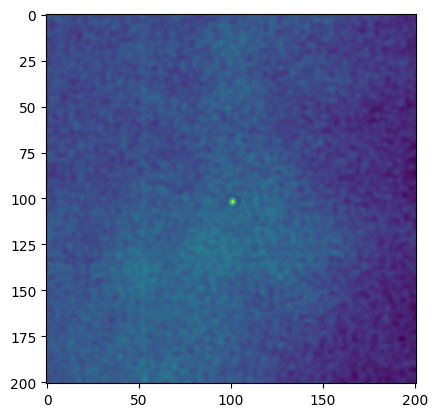

In [66]:
to_optimize = matrices[15].clone().detach().requires_grad_(True)
project_matrix_optimizer = torch.optim.Adam(
    params= [to_optimize,],
    lr=0.0005
)

proj_image = torch.zeros(im.shape[0], im.shape[1], device=device,requires_grad=True)
for j in range(500):
    proj_image = torch.zeros(im.shape[0], im.shape[1], device=device,requires_grad=True)
    project_matrix_optimizer.zero_grad()
    projection = torch.mm(to_optimize, r_aunps.T).T[:,[0,1]]
    
    
    
    for i in range(projection.shape[0]):
        inv_co = torch.flip(projection[i], [0])
        proj_image = proj_image - shift_2d(circle, shifts=inv_co)
    image_product = torch.fft.fft2(im) * torch.fft.fft2(proj_image).conj()
    cc_image = torch.fft.fftshift(torch.fft.ifft2(image_product))
    sub= cc_image.real[cc_image.real.shape[0]//2-100:cc_image.real.shape[0]//2+101,cc_image.real.shape[1]//2-100:cc_image.real.shape[1]//2+101]
    ph= torch.log_softmax(sub,dim=0).min()
    loss = ph
    
    #cc_value = (proj_image * im).sum()
    loss.backward()
    project_matrix_optimizer.step()
    if j % 20 == 0:
        print(j, loss.item())
        plt.imshow(proj_image.cpu().detach())
        plt.imshow(sub.cpu().detach())
        plt.show()

In [56]:
to_optimize

tensor([[-1.6755e-01, -9.9293e-01, -6.8974e-03,  4.9933e+03],
        [ 9.8819e-01, -1.6482e-01,  6.6713e-03,  4.5173e+02],
        [ 1.2217e-02,  0.0000e+00,  9.9993e-01, -5.1955e+02],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]], device='cuda:0',
       dtype=torch.float64, requires_grad=True)

In [22]:
matrices[15]

tensor([[-1.5944e-01, -9.8720e-01,  1.9481e-03,  4.9934e+03],
        [ 9.8713e-01, -1.5945e-01, -1.2061e-02,  4.5169e+02],
        [ 1.2217e-02,  0.0000e+00,  9.9993e-01, -5.1955e+02],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]], device='cuda:0',
       dtype=torch.float64, grad_fn=<SelectBackward0>)

In [161]:
tilt = 6
shift = plot_cc(im_data[tilt].to(device).detach(),matrices[tilt],aunps,r=5)
print(shift)
new =  matrices[tilt].clone().detach()
new[0,3] += shift[1]
new[1,3] += shift[0]
shift = plot_cc(im_data[tilt].to(device).detach(),new,aunps,r=5,show_ccpeak=True)
print(shift)

[3. 0.]
[0. 0.]


In [158]:
matrices[tilt]

tensor([[-1.5157e-01, -9.8701e-01,  5.3286e-02,  4.9469e+03],
        [ 9.3114e-01, -1.6066e-01, -3.2736e-01,  6.8530e+02],
        [ 3.3167e-01,  0.0000e+00,  9.4340e-01, -1.0298e+03],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]], device='cuda:0',
       dtype=torch.float64, grad_fn=<SelectBackward0>)

In [155]:
new

tensor([[-1.4891e-01, -9.8695e-01,  6.1256e-02,  4.9184e+03],
        [ 9.1274e-01, -1.6102e-01, -3.7546e-01,  8.2387e+02],
        [ 3.8042e-01,  0.0000e+00,  9.2481e-01, -1.1027e+03],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]], device='cuda:0',
       dtype=torch.float64)

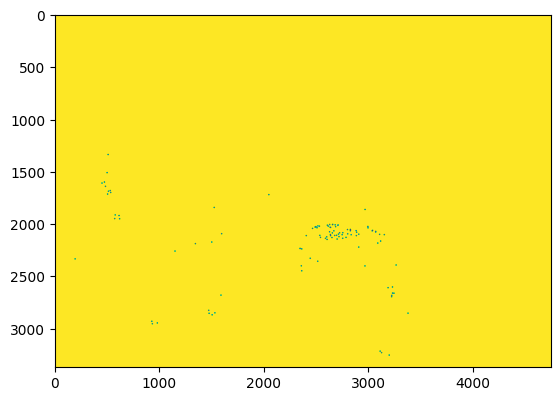

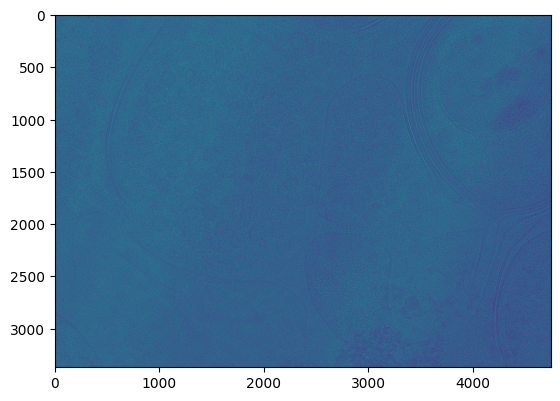

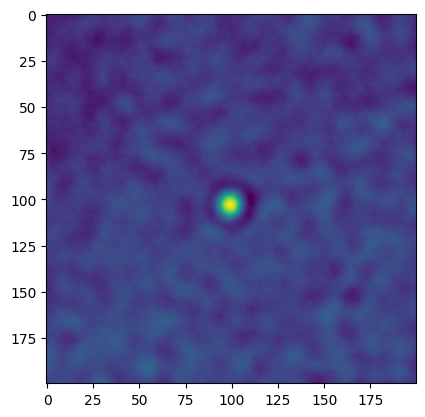

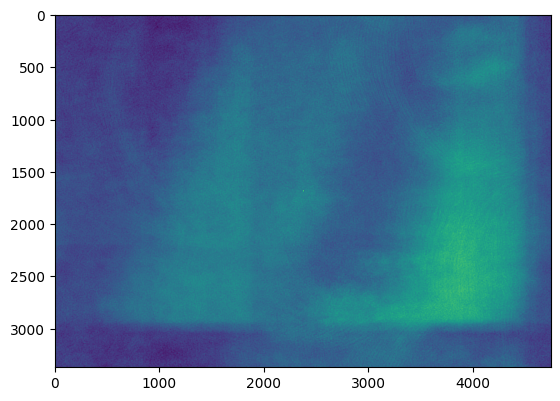

[ 3. -1.]
tensor([[103,  99]], device='cuda:0')
tensor(31825660., device='cuda:0')
tensor(31826268., device='cuda:0')


In [96]:
plot_cc(im_data[15].to(device).detach(),to_optimize,aunps,r=5.3)

In [68]:
to_optimize

tensor([[-1.6035e-01, -9.8619e-01, -1.3988e-03,  4.9933e+03],
        [ 9.8806e-01, -1.5993e-01, -1.2319e-02,  4.5177e+02],
        [ 1.2217e-02,  0.0000e+00,  9.9993e-01, -5.1955e+02],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]], device='cuda:0',
       dtype=torch.float64, requires_grad=True)

In [121]:
from libtilt.transformations import T

add_trans = T([0,3,1]).type(torch.float64).to(device)

In [122]:
new =  torch.linalg.inv(add_trans @ torch.linalg.inv(to_optimize))

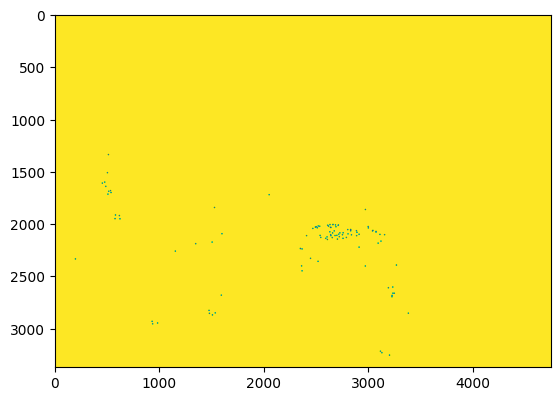

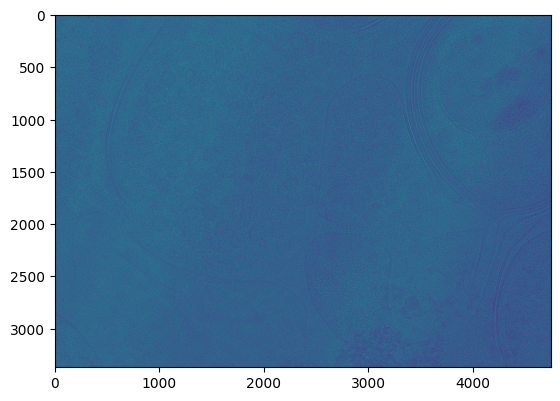

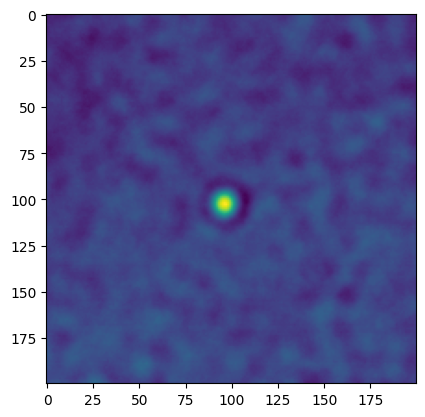

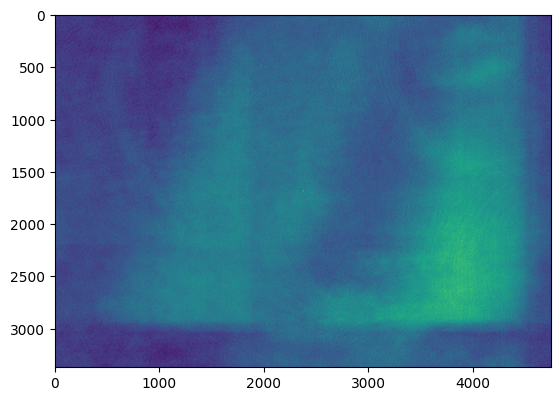

[ 3. -4.]
tensor([[103,  96]], device='cuda:0')
tensor(31824980., device='cuda:0')
tensor(31826236., device='cuda:0')


In [123]:
plot_cc(im_data[15].to(device).detach(),new,aunps,r=8.3)